In [1]:
import os
import numpy as np
import pandas as pd
import tifffile
import matplotlib.pyplot as plt

def load_tiff_frame(path, index):
    """Load one frame (page) from a multi-page TIFF without reading the rest."""
    with tifffile.TiffFile(path) as tif:
        n = len(tif.pages)
        if not -n <= index < n:
            raise IndexError(f"Frame {index} out of range (file has {n} frames)")
        return tif.pages[index].asarray(),n

def get_file_list(dir,ending=".tif"):
    #dir = '/Volumes/Samsung_T3/Olivias/CMOS PTC/'
    file_list = []
    for file in os.listdir(dir):
        if file.endswith(ending):
            file_name = dir + '/' +file
            file_list.append(file_name)
    return file_list

def get_stack(filename,start=1):
    stack = []
    data, n = load_tiff_frame(filename,0)
    for I in range(start,n):
        data = load_tiff_frame(filename,I)
        stack.append(data[0])
    return np.asarray(stack).swapaxes(0,2)


In [5]:
files = get_file_list("/Users/ashleycadby/PycharmProjects/EMCCD_Noise/PTC_60")
data = get_stack(files[0])

In [6]:
noise_data = []
signal_data = []
for filename in files:
    back_data = get_stack(filename)[0]
    data = get_stack(filename)
    temp_data = data - back_data
    data = data - np.min(temp_data)
    signal = np.mean(data,axis=2)
    noise  = np.var(data,axis=2)
    noise_data.append(noise)
    signal_data.append(signal)

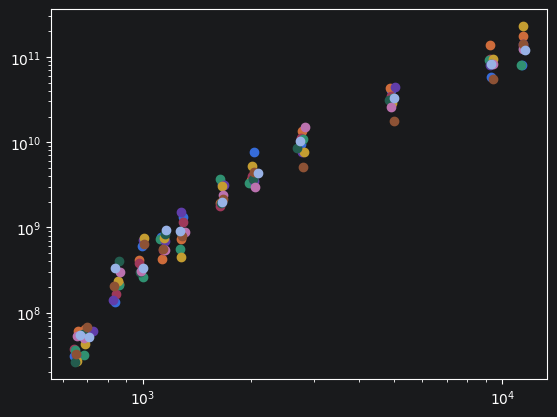

In [8]:
real_signal = np.asarray(signal_data)
real_noise = np.asarray(noise_data)
plt.loglog(real_signal[:,100:110,100],real_noise[:,100:110,100]**2,'o')